# Week 08：支持向量机

## 支持向量机分类算法——基于手写数字数据的图像分类

### 1. 实验目的

本实验使用 Digits 手写数字数据集完成 0～9 的多分类任务，学习并实践支持向量机（Support Vector Machine，SVM）分类算法。

主要实验内容：

1. 理解支持向量机、分类超平面、间隔和支持向量的基本概念；
2. 了解线性 SVM 的基本分类思想；
3. 理解核函数在非线性分类中的作用；
4. 使用线性核和 RBF 核完成手写数字分类；
5. 分析参数 C 和 gamma 对 SVM 性能的影响；
6. 使用 Accuracy、混淆矩阵和分类报告评价模型；
7. 比较不同核函数下 SVM 的分类效果。

### 2. 数据集加载与探索

本实验使用 scikit-learn 内置的 Digits 手写数字数据集。

数据集中每个样本是一张 8×8 像素的灰度手写数字图像，每张图像可以展开为 64 个像素特征，分类目标为数字 0～9，因此这是一个多分类任务。

In [1]:
from sklearn.datasets import load_digits
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

digits = load_digits()

X = digits.data
y = digits.target

print("特征数据形状：", X.shape)
print("标签数据形状：", y.shape)
print("单张图片形状：", digits.images[0].shape)
print("类别：", digits.target_names)

特征数据形状： (1797, 64)
标签数据形状： (1797,)
单张图片形状： (8, 8)
类别： [0 1 2 3 4 5 6 7 8 9]


### 3. 手写数字图像可视化

为了直观理解 Digits 数据集，将部分 8×8 手写数字图像进行可视化。每张图像对应一个 0～9 的类别标签。

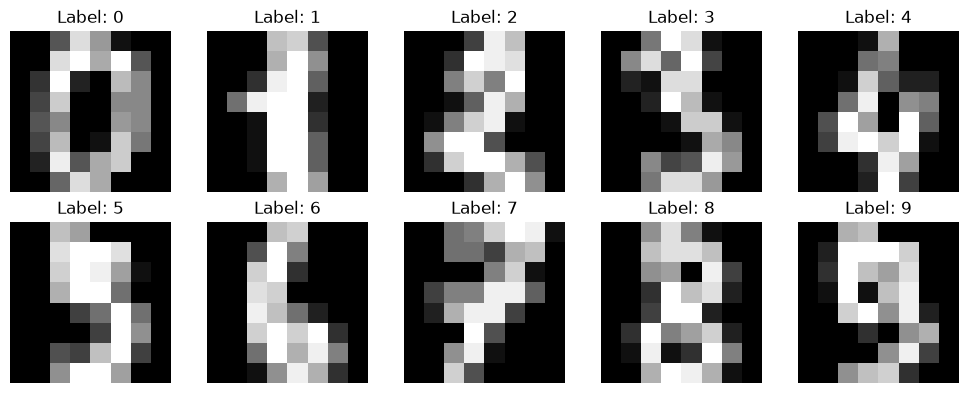

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
print("第一张图片的二维像素矩阵：")
print(digits.images[0])

print("\n第一张图片展开后的 64 个特征：")
print(X[0])

第一张图片的二维像素矩阵：
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]

第一张图片展开后的 64 个特征：
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


### 4. 类别分布分析

统计 0～9 各类别的样本数量，观察数据集是否存在明显的类别不平衡问题。

In [4]:
class_counts = pd.Series(y).value_counts().sort_index()

print("各类别样本数量：")
print(class_counts)

print("\n各类别样本比例：")
print((class_counts / len(y) * 100).round(2))

各类别样本数量：
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

各类别样本比例：
0     9.91
1    10.13
2     9.85
3    10.18
4    10.07
5    10.13
6    10.07
7     9.96
8     9.68
9    10.02
Name: count, dtype: float64


### 5. 训练集与测试集划分

将数据集按照 80% : 20% 划分为训练集和测试集，并采用分层抽样，使 0～9 各类别在训练集和测试集中保持合理的比例。

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("训练集形状：", X_train.shape)
print("测试集形状：", X_test.shape)

print("\n训练集类别分布：")
print(pd.Series(y_train).value_counts().sort_index())

print("\n测试集类别分布：")
print(pd.Series(y_test).value_counts().sort_index())

训练集形状： (1437, 64)
测试集形状： (360, 64)

训练集类别分布：
0    142
1    146
2    142
3    146
4    145
5    145
6    145
7    143
8    139
9    144
Name: count, dtype: int64

测试集类别分布：
0    36
1    36
2    35
3    37
4    36
5    37
6    36
7    36
8    35
9    36
Name: count, dtype: int64


### 6. 线性支持向量机

首先使用线性核构建支持向量机分类模型。线性 SVM 尝试在特征空间中寻找具有较大分类间隔的决策边界。

本实验首先使用默认的 C=1.0，观察线性 SVM 在 Digits 手写数字数据集上的分类效果。

In [6]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear_svm = SVC(
    kernel="linear",
    C=1.0
)

linear_svm.fit(X_train, y_train)

y_train_pred = linear_svm.predict(X_train)
y_test_pred = linear_svm.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"训练集 Accuracy：{train_accuracy * 100:.2f}%")
print(f"测试集 Accuracy：{test_accuracy * 100:.2f}%")

训练集 Accuracy：100.00%
测试集 Accuracy：97.78%


### 7. 支持向量分析

支持向量是距离分类边界较近、对 SVM 决策边界起关键作用的训练样本。

通过模型中的支持向量信息，观察各类别参与确定分类边界的支持向量数量。

In [7]:
print("各类别支持向量数量：")
print(linear_svm.n_support_)

print("\n支持向量总数量：")
print(linear_svm.n_support_.sum())

print("\n训练样本总数量：")
print(len(X_train))

print("\n支持向量占训练集比例：")
print(f"{linear_svm.n_support_.sum() / len(X_train) * 100:.2f}%")

各类别支持向量数量：
[25 50 42 39 42 40 26 35 50 51]

支持向量总数量：
400

训练样本总数量：
1437

支持向量占训练集比例：
27.84%


### 8. RBF 核支持向量机

线性核只能构建线性决策边界，而 RBF（Radial Basis Function）核可以处理更加复杂的非线性关系。

本实验使用 RBF 核训练 SVM，并与线性核 SVM 的分类性能进行比较。

In [8]:
rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

rbf_svm.fit(X_train, y_train)

rbf_train_pred = rbf_svm.predict(X_train)
rbf_test_pred = rbf_svm.predict(X_test)

rbf_train_accuracy = accuracy_score(y_train, rbf_train_pred)
rbf_test_accuracy = accuracy_score(y_test, rbf_test_pred)

print(f"RBF SVM 训练集 Accuracy：{rbf_train_accuracy * 100:.2f}%")
print(f"RBF SVM 测试集 Accuracy：{rbf_test_accuracy * 100:.2f}%")

print("\nRBF SVM 支持向量总数量：")
print(rbf_svm.n_support_.sum())

print("\n支持向量占训练集比例：")
print(f"{rbf_svm.n_support_.sum() / len(X_train) * 100:.2f}%")

RBF SVM 训练集 Accuracy：99.79%
RBF SVM 测试集 Accuracy：99.17%

RBF SVM 支持向量总数量：
663

支持向量占训练集比例：
46.14%


### 9. C 和 gamma 参数实验

对于 RBF 核 SVM，C 控制模型对训练样本分类错误的惩罚程度，gamma 控制单个训练样本的影响范围。

本实验设置不同的 C 和 gamma 组合，比较模型在训练集和测试集上的分类准确率，观察参数变化对模型性能的影响。

In [9]:
C_values = [0.1, 1, 10, 100]
gamma_values = [0.0001, 0.001, 0.01, 0.1]

results = []

for C in C_values:
    for gamma in gamma_values:
        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma
        )

        model.fit(X_train, y_train)

        train_acc = accuracy_score(
            y_train,
            model.predict(X_train)
        )

        test_acc = accuracy_score(
            y_test,
            model.predict(X_test)
        )

        results.append({
            "C": C,
            "gamma": gamma,
            "Train Accuracy": train_acc,
            "Test Accuracy": test_acc
        })

results_df = pd.DataFrame(results)

display(results_df)

,C,gamma,Train Accuracy,Test Accuracy
0,0.1,0.0001,0.917189,0.900000
1,0.1,0.0010,0.973556,0.975000
2,0.1,0.0100,0.154489,0.122222
3,0.1,0.1000,0.203201,0.102778
4,1.0,0.0001,0.979819,0.980556
5,1.0,0.0010,0.998608,0.988889
6,1.0,0.0100,1.000000,0.847222
7,1.0,0.1000,1.000000,0.113889
8,10.0,0.0001,0.997912,0.991667
9,10.0,0.0010,1.000000,0.991667


### 10. 最终 RBF SVM 模型

通过比较不同 C 和 gamma 参数组合，在本次实验的固定数据划分下，测试集最高准确率为 99.17%。

本实验选择 `C=10`、`gamma=0.0001` 构建最终 RBF SVM 模型。

需要注意的是，本实验主要用于观察不同参数对 SVM 性能的影响，因此直接比较了测试集结果。更严格的机器学习实验应使用验证集或交叉验证选择模型参数，再使用测试集评价最终模型。

In [10]:
final_svm = SVC(
    kernel="rbf",
    C=10,
    gamma=0.0001
)

final_svm.fit(X_train, y_train)

final_train_pred = final_svm.predict(X_train)
final_test_pred = final_svm.predict(X_test)

print(
    f"最终模型训练集 Accuracy："
    f"{accuracy_score(y_train, final_train_pred) * 100:.2f}%"
)

print(
    f"最终模型测试集 Accuracy："
    f"{accuracy_score(y_test, final_test_pred) * 100:.2f}%"
)

print("支持向量总数量：", final_svm.n_support_.sum())

最终模型训练集 Accuracy：99.79%
最终模型测试集 Accuracy：99.17%
支持向量总数量： 485


### 11. 最终模型评价

使用混淆矩阵和分类报告进一步评价最终 RBF SVM 模型，分析模型在数字 0～9 各类别上的分类性能。

In [11]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, final_test_pred)

print("混淆矩阵：")
print(cm)

print("\n分类报告：")
print(classification_report(y_test, final_test_pred))

混淆矩阵：
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  2  0  0  0  0  0  0 33  0]
 [ 0  0  0  0  0  0  0  1  0 35]]

分类报告：
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.94      0.97        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   mac

### 12. 错误分类样本分析

最终模型在 360 个测试样本中正确分类 357 个，仅有 3 个样本分类错误。

下面对错误分类的手写数字图像进行可视化，观察模型容易混淆的数字及其图像特征。

错误分类样本数量： 3
错误样本位置： [ 51  93 127]


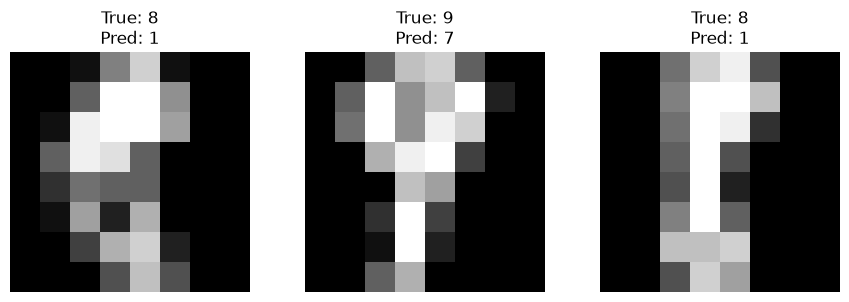

In [12]:
# 找出预测错误样本的位置
wrong_indices = np.where(final_test_pred != y_test)[0]

print("错误分类样本数量：", len(wrong_indices))
print("错误样本位置：", wrong_indices)

# 显示错误分类的图片
fig, axes = plt.subplots(
    1,
    len(wrong_indices),
    figsize=(9, 3)
)

for ax, index in zip(axes, wrong_indices):
    image = X_test[index].reshape(8, 8)

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {y_test[index]}\n"
        f"Pred: {final_test_pred[index]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

#### 错误样本分析

最终 RBF SVM 在 360 个测试样本中正确分类 357 个，仅有 3 个样本分类错误，测试集准确率达到 99.17%。

从错误样本可以看出：

- 2 个真实数字 8 被错误预测为数字 1；
- 1 个真实数字 9 被错误预测为数字 7；
- 部分错误样本的书写形态与标准数字存在一定差异，例如数字 8 的局部笔画呈现出较明显的竖直结构，可能导致模型将其与数字 1 混淆。

总体来看，最终模型对绝大多数手写数字都能够正确分类，仅在少量书写形态较特殊的样本上出现错误。

## 13. 实验总结

本实验基于 sklearn 的 Digits 手写数字数据集，使用支持向量机（SVM）完成了 0～9 共 10 个类别的手写数字分类任务。

实验首先对数据集进行了基本探索和图像可视化，并按照 8:2 的比例划分训练集和测试集。随后分别使用线性核和 RBF 核构建 SVM 分类模型。

在线性核 SVM 实验中，模型训练集准确率达到 100.00%，测试集准确率达到 97.78%，共有 400 个支持向量，占训练集的 27.84%。

使用 RBF 核后，模型表现进一步提升。通过比较不同 C 和 gamma 参数组合，最终选择 C=10、gamma=0.0001。在本次固定数据划分下，最终模型训练集准确率为 99.79%，测试集准确率为 99.17%，共有 485 个支持向量。

参数实验表明，C 和 gamma 会明显影响 SVM 的分类性能。当参数设置不合适时，模型可能出现欠拟合或过拟合。例如 gamma 过大时，部分模型虽然训练集准确率达到 100%，但测试集准确率明显下降，说明训练集准确率高并不代表模型具有良好的泛化能力。

最终模型在 360 个测试样本中正确分类 357 个，仅错误分类 3 个。其中 2 个真实数字 8 被预测为数字 1，1 个真实数字 9 被预测为数字 7。通过错误样本可视化可以发现，部分手写数字的书写形态较为特殊，可能增加模型分类的难度。

通过本次实验，我进一步理解了 SVM 中分类超平面、最大间隔、支持向量、软间隔、核函数等基本概念，并掌握了参数 C 和 gamma 对模型复杂度及泛化能力的影响。同时认识到，在评价分类模型时不能只关注训练集准确率，还需要结合测试集准确率、混淆矩阵、Precision、Recall 和 F1-score 等指标综合分析模型性能。

需要说明的是，本实验为了直观观察参数变化对模型性能的影响，直接比较了不同参数在测试集上的表现。更加严格的机器学习实验应使用验证集或交叉验证选择模型参数，并将测试集仅用于最终模型评价。